In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
url='/content/insurance.csv'
df=pd.read_csv(url)

In [ ]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [ ]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [ ]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [ ]:
numerical_col=['age', 'bmi','charges']

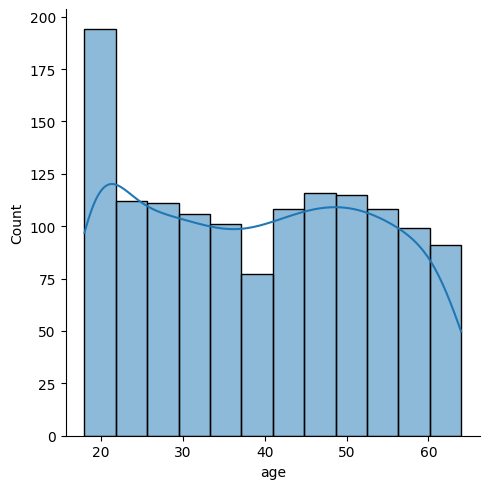

In [ ]:
sns.displot(df["age"],kde=True)


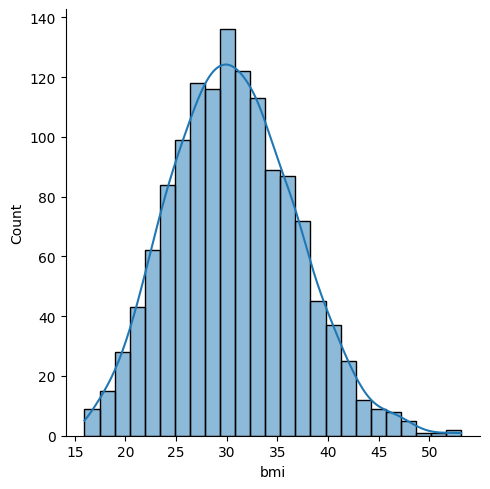

In [ ]:
sns.displot(df["bmi"],kde=True)

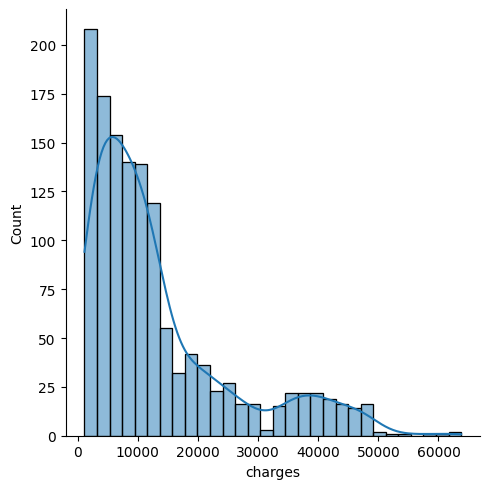

In [ ]:
sns.displot(df["charges"],kde=True)

In [ ]:
df.sample(5)

,age,bmi,children,charges,is_male,is_smoker,southeast,southwest,northwest,northeast,bmi_carte_normal,bmi_carte_overweight,bmi_carte_obese
227,1.338082,0.684211,-0.908614,24227,0,0,0,0,1,0,0,0,1
1304,0.198863,0.236842,0.751079,21259,1,1,1,0,0,0,1,0,0
1055,1.124479,0.315789,-0.908614,10594,1,0,0,1,0,0,0,1,0
434,-0.584350,0.342105,-0.078767,4243,1,0,0,1,0,0,0,1,0
169,-0.869155,0.078947,1.580926,4827,1,0,1,0,0,0,0,0,0


<Axes: xlabel='sex', ylabel='count'>

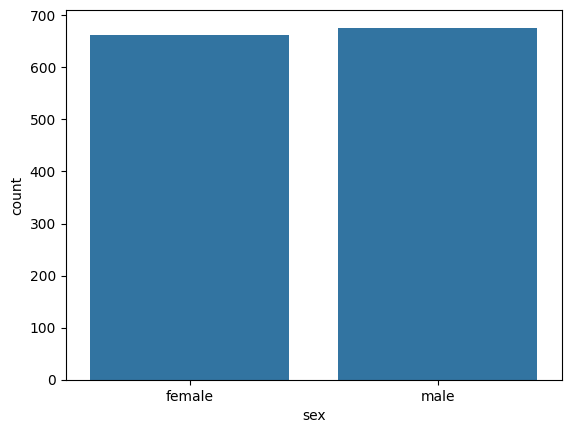

In [ ]:
sns.countplot(x=df['sex'])

<Axes: xlabel='children'>

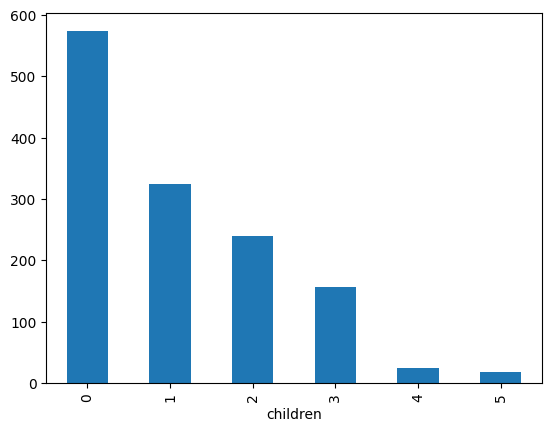

In [ ]:
df['children'].value_counts().plot(kind="bar")

<Axes: xlabel='smoker', ylabel='count'>

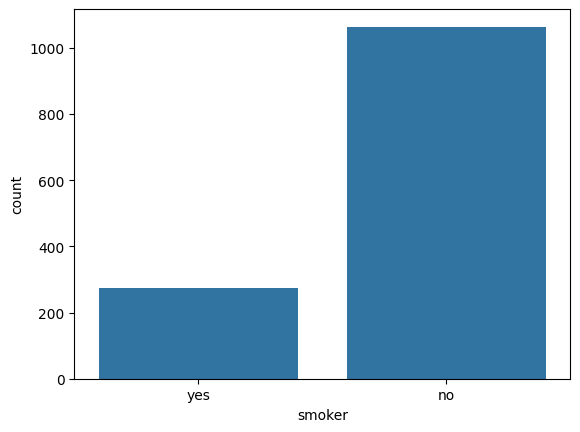

In [ ]:
sns.countplot(x=df['smoker'])

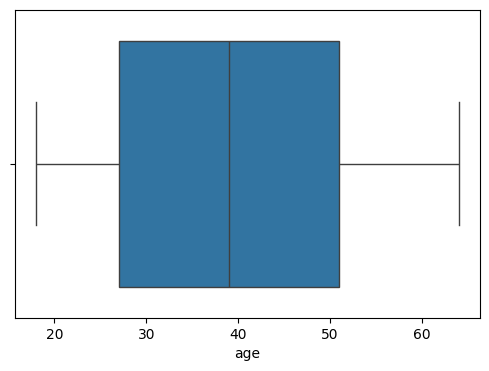

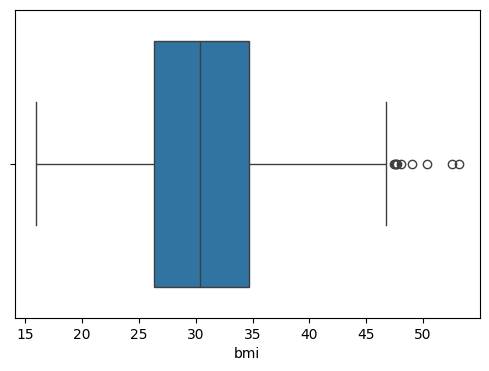

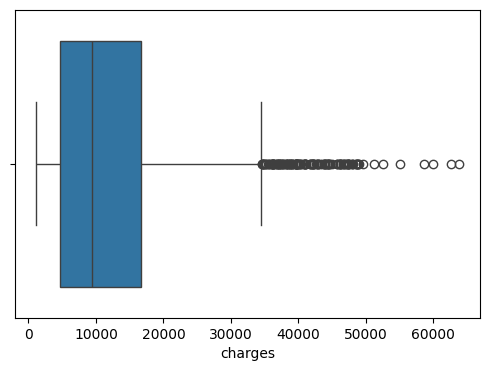

In [ ]:
for col in numerical_col:
  plt.figure(figsize=(6,4))
  sns.boxplot(x=df[col])

<Axes: >

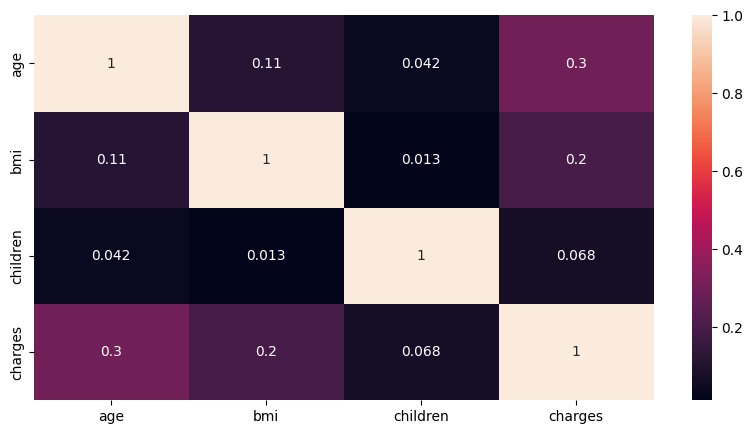

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(df.select_dtypes(include='number').corr(),annot=True)

In [ ]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['is_male']=le.fit_transform(df['sex'])

In [ ]:
df.head(2)

,age,sex,bmi,children,smoker,region,charges,is_male
0,19,female,27.90,0,yes,southwest,16884.9240,0
1,18,male,33.77,1,no,southeast,1725.5523,1


In [ ]:
df['is_smoker']=df['smoker'].map({'yes':1,'no':0})

In [ ]:
df.head()

,age,sex,bmi,children,smoker,region,charges,is_male,is_smoker
0,19,female,27.900,0,yes,southwest,16884.92400,0,1
1,18,male,33.770,1,no,southeast,1725.55230,1,0
2,28,male,33.000,3,no,southeast,4449.46200,1,0
3,33,male,22.705,0,no,northwest,21984.47061,1,0
4,32,male,28.880,0,no,northwest,3866.85520,1,0


In [ ]:
df.drop(columns=['sex','smoker'],inplace=True)

In [ ]:
df['region'].value_counts()

,count
region,
southeast,364
southwest,325
northwest,325
northeast,324


In [ ]:
from sklearn.preprocessing import OneHotEncoder
oh=OneHotEncoder()
array=oh.fit_transform(df[['region']]).toarray()
array_df=pd.DataFrame(array,columns=['southeast','southwest','northwest','northeast'])
df=pd.concat([df,array_df],axis=1)
#or i can df=pd.get_dummies(df,columns=['region'],drop_frist=True)

In [ ]:
df.head(2)

,age,bmi,children,region,charges,is_male,is_smoker,southeast,southwest,northwest,northeast
0,19,27.90,0,southwest,16884.9240,0,1,0.0,0.0,0.0,1.0
1,18,33.77,1,southeast,1725.5523,1,0,0.0,0.0,1.0,0.0


In [ ]:
df.drop(columns=['region'],inplace=True)

In [ ]:
df.head(2)

,age,bmi,children,charges,is_male,is_smoker,southeast,southwest,northwest,northeast
0,19,27.90,0,16884.9240,0,1,0.0,0.0,0.0,1.0
1,18,33.77,1,1725.5523,1,0,0.0,0.0,1.0,0.0


In [ ]:
df=df.astype(int)
df.head(5)

,age,bmi,children,charges,is_male,is_smoker,southeast,southwest,northwest,northeast
0,19,27,0,16884,0,1,0,0,0,1
1,18,33,1,1725,1,0,0,0,1,0
2,28,33,3,4449,1,0,0,0,1,0
3,33,22,0,21984,1,0,0,1,0,0
4,32,28,0,3866,1,0,0,1,0,0


In [ ]:
df['bmi_carte']=pd.cut(df['bmi'],bins=[0,18,25,30,float('inf')],labels=['underweight','normal','overweight','obese'])

In [ ]:
df.head()

,age,bmi,children,charges,is_male,is_smoker,southeast,southwest,northwest,northeast,bmi_carte
0,19,27,0,16884,0,1,0,0,0,1,overweight
1,18,33,1,1725,1,0,0,0,1,0,obese
2,28,33,3,4449,1,0,0,0,1,0,obese
3,33,22,0,21984,1,0,0,1,0,0,normal
4,32,28,0,3866,1,0,0,1,0,0,overweight


In [ ]:
df=pd.get_dummies(df,columns=['bmi_carte'],drop_first=True)

In [ ]:
df.head(3)

,age,bmi,children,charges,is_male,is_smoker,southeast,southwest,northwest,northeast,bmi_carte_normal,bmi_carte_overweight,bmi_carte_obese
0,19,27,0,16884,0,1,0,0,0,1,False,True,False
1,18,33,1,1725,1,0,0,0,1,0,False,False,True
2,28,33,3,4449,1,0,0,0,1,0,False,False,True


In [ ]:
df=df.astype(int)

In [ ]:
df.head()

,age,bmi,children,charges,is_male,is_smoker,southeast,southwest,northwest,northeast,bmi_carte_normal,bmi_carte_overweight,bmi_carte_obese
0,19,27,0,16884,0,1,0,0,0,1,0,1,0
1,18,33,1,1725,1,0,0,0,1,0,0,0,1
2,28,33,3,4449,1,0,0,0,1,0,0,0,1
3,33,22,0,21984,1,0,0,1,0,0,1,0,0
4,32,28,0,3866,1,0,0,1,0,0,0,1,0


In [ ]:
from sklearn.preprocessing import MinMaxScaler
ss=MinMaxScaler()
df['bmi']=ss.fit_transform(df[['bmi']])


In [ ]:
df.head()

,age,bmi,children,charges,is_male,is_smoker,southeast,southwest,northwest,northeast,bmi_carte_normal,bmi_carte_overweight,bmi_carte_obese
0,19,0.315789,0,16884,0,1,0,0,0,1,0,1,0
1,18,0.473684,1,1725,1,0,0,0,1,0,0,0,1
2,28,0.473684,3,4449,1,0,0,0,1,0,0,0,1
3,33,0.184211,0,21984,1,0,0,1,0,0,1,0,0
4,32,0.342105,0,3866,1,0,0,1,0,0,0,1,0


In [ ]:
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()
df['age']=ss.fit_transform(df[['age']])
df['children']=ss.fit_transform(df[['children']])

In [ ]:
df.head()

,age,bmi,children,charges,is_male,is_smoker,southeast,southwest,northwest,northeast,bmi_carte_normal,bmi_carte_overweight,bmi_carte_obese
0,-1.438764,0.315789,-0.908614,16884,0,1,0,0,0,1,0,1,0
1,-1.509965,0.473684,-0.078767,1725,1,0,0,0,1,0,0,0,1
2,-0.797954,0.473684,1.580926,4449,1,0,0,0,1,0,0,0,1
3,-0.441948,0.184211,-0.908614,21984,1,0,0,1,0,0,1,0,0
4,-0.513149,0.342105,-0.908614,3866,1,0,0,1,0,0,0,1,0


In [ ]:
from sklearn.model_selection import train_test_split
X=df.drop(columns=['charges'],axis=1)
Y=df['charges']
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=.2,random_state=42)

In [ ]:
print(Y_train)

560      9193
1285     8534
1142    27117
969      8596
486     12475
        ...  
1095     4561
1130     8582
1294    11931
860     46113
1126    10214
Name: charges, Length: 1070, dtype: int64


In [ ]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,Y_train)

LinearRegression()

In [ ]:
y_pred=model.predict(X_test)
from sklearn.metrics import mean_squared_error, r2_score
mse = mean_squared_error(Y_test, y_pred)
r2 = r2_score(Y_test, y_pred)

print("Mean Squared Error:", mse)
print("R² Score:", r2)

Mean Squared Error: 33333689.178549867
R² Score: 0.7852880585925358
